In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as p

In [15]:
df=pd.read_csv(r"C:\Users\SPTINT-20\Desktop\fish_test.csv")
df

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340
...,...,...,...,...,...,...,...
154,Smelt,12.2,11.5,12.2,13.4,2.0904,1.3936
155,Smelt,13.4,11.7,12.4,13.5,2.4300,1.2690
156,Smelt,12.2,12.1,13.0,13.8,2.2770,1.2558
157,Smelt,19.7,13.2,14.3,15.2,2.8728,2.0672


In [39]:
x=df.iloc[:,1:7].values

In [49]:
x.shape

(159, 6)

In [40]:
wcss=[]

In [41]:
from sklearn.cluster import KMeans

In [42]:
for i in range(1,11):
    kmeans=KMeans(n_clusters=i,init='k-means++',random_state=42)
    kmeans.fit(x)
    wcss.append(kmeans.inertia_)

C:\Users\SPTINT-20\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\SPTINT-20\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\SPTINT-20\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\SPTINT-20\AppData\Roaming\Python\Python313\site-packages\s

C:\Users\SPTINT-20\AppData\Local\Temp\ipykernel_17196\2084478007.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  p.legend()


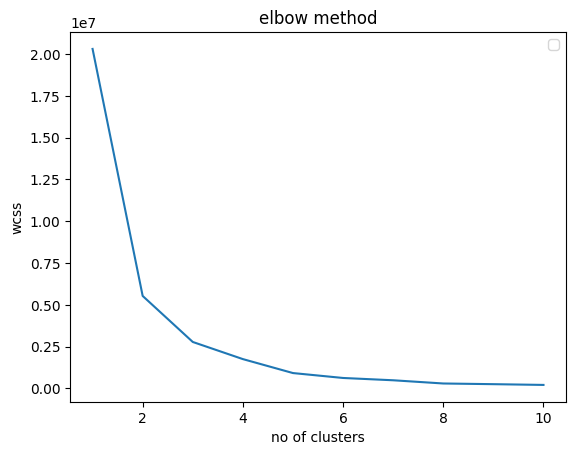

In [43]:
p.plot(range(1,11),wcss)
p.title("elbow method")
p.xlabel("no of clusters")
p.ylabel("wcss")
p.legend()
p.show()

In [44]:
kmeans=KMeans(n_clusters=5,init='k-means++',random_state=42)
y_pred=kmeans.fit_predict(x)



C:\Users\SPTINT-20\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


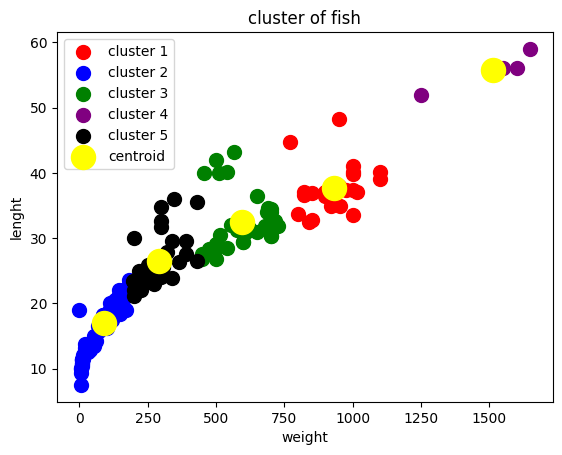

In [51]:
p.scatter(x[y_pred==0,0],x[y_pred==0,1],s=100,c='red',label='cluster 1')
p.scatter(x[y_pred==1,0],x[y_pred==1,1],s=100,c='blue',label='cluster 2')
p.scatter(x[y_pred==2,0],x[y_pred==2,1],s=100,c='green',label='cluster 3')
p.scatter(x[y_pred==3,0],x[y_pred==3,1],s=100,c='purple',label='cluster 4')
p.scatter(x[y_pred==4,0],x[y_pred==4,1],s=100,c='black',label='cluster 5')
p.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],s=300,c='yellow',label='centroid')
p.title("cluster of fish")
p.xlabel("weight")
p.ylabel("lenght")
p.legend()
p.show()